## Decision Tree

I will be using Decision Tree modelling to  visualise loyalty point drivers.

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

In [2]:
# Load the dataset
df = pd.read_csv("data/cleaned_turtle_reviews.csv")
df.head()

,gender,age,remuneration,spending_score,loyalty_points,education,product,review,summary
0,Male,18,12.30,39,210,Graduate,453,"When it comes to a DM's screen, the space on t...",The fact that 50% of this space is wasted on a...
1,Male,23,12.30,81,524,Graduate,466,An Open Letter to GaleForce9*:\n\nYour unpaint...,Another worthless Dungeon Master's screen from...
2,Female,22,13.12,6,40,Graduate,254,"Nice art, nice printing. Why two panels are f...","pretty, but also pretty useless"
3,Female,25,13.12,77,562,Graduate,263,Amazing buy! Bought it as a gift for our new d...,Five Stars
4,Female,33,13.94,40,366,Graduate,291,As my review of GF9's previous screens these w...,Money trap


## Data Splitting

In [3]:
# Separate the data into features and target
X = df.drop(columns=['loyalty_points', 'product', 'review', 'summary'])
y = df['loyalty_points']

In [4]:
# Show X - Note the uppercase
X

,gender,age,remuneration,spending_score,education
0,Male,18,12.30,39,Graduate
1,Male,23,12.30,81,Graduate
2,Female,22,13.12,6,Graduate
3,Female,25,13.12,77,Graduate
4,Female,33,13.94,40,Graduate
...,...,...,...,...,...
1995,Female,37,84.46,69,PhD
1996,Female,43,92.66,8,PhD
1997,Male,34,92.66,91,Graduate
1998,Male,34,98.40,16,PhD


In [5]:
# Show y - Note the lowercase
y

0        210
1        524
2         40
3        562
4        366
        ... 
1995    4031
1996     539
1997    5614
1998    1048
1999     479
Name: loyalty_points, Length: 2000, dtype: int64

In [6]:
# Split the data into training (80%) and test-validation (20%) sets
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, random_state=42)

# Split the test-validation set (20%) into validation (10%) and test (10%) sets
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

In [7]:
# Display the shapes of the splits to verify
print("Training set shape:", X_train.shape, y_train.shape)
print("Validation set shape:", X_val.shape, y_val.shape)
print("Test set shape:", X_test.shape, y_test.shape)

Training set shape: (1600, 5) (1600,)
Validation set shape: (200, 5) (200,)
Test set shape: (200, 5) (200,)


## Feature Scaling

Feature scaling (e.g. StandardScaler) is not required, as decision trees split on feature thresholds and are therefore unaffected by differences in feature scale.

## Feature Encoding

`gender` is one-hot encoded because its categories have no natural order, while `education` is ordinal encoded to preserve the ranking of qualification levels (e.g. diploma < graduate < postgraduate < PhD).

In [8]:
# Define nominal features to be one-hot encoded
nominal_features = ['gender']

# Define ordinal features to be ordinally encoded
ordinal_features = ['education']

# Define the ordinal categories for education
education_categories = ['Basic', 'Diploma', 'Graduate', 'Postgraduate', 'PhD']

# Define passthrough features that will not be transformed
passthrough_features = ['age', 'remuneration', 'spending_score']

# Create a nominal transformer pipeline
nominal_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Create an ordinal transformer pipeline
ordinal_transformer = Pipeline(steps=[
    ('ordinal', OrdinalEncoder(categories=[education_categories], handle_unknown='use_encoded_value', unknown_value=-1))  
])

In [9]:
# Combine transformers into a single ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('nom', nominal_transformer, nominal_features),
        ('ord', ordinal_transformer, ordinal_features),
        ('pass', 'passthrough', passthrough_features) # Pass through the storey_range feature without transformation
    ],
    remainder='passthrough',
    n_jobs=-1
    )

## Baseline Model

In [10]:
# Create the pipeline with a decision tree model
dt_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', DecisionTreeRegressor())
])

# Fit the pipeline to the training data
dt_pipeline.fit(X_train, y_train)

# Predict on the validation set with Decision Tree
y_val_pred_dt = dt_pipeline.predict(X_val)

# Calculate regression metrics for validation set with Decision Tree
val_mae_dt = mean_absolute_error(y_val, y_val_pred_dt)
val_mse_dt = mean_squared_error(y_val, y_val_pred_dt)
val_rmse_dt = root_mean_squared_error(y_val, y_val_pred_dt) # RMSE is the square root of MSE
val_r2_dt = r2_score(y_val, y_val_pred_dt)

# Display the metrics for Decision Tree
print("Decision Tree Validation Metrics:")
print(f"Decision Tree MAE: {val_mae_dt}")
print(f"Decision Tree MSE: {val_mse_dt}")
print(f"Decision Tree RMSE: {val_rmse_dt}")
print(f"Decision Tree R²: {val_r2_dt}")

Decision Tree Validation Metrics:
Decision Tree MAE: 21.645
Decision Tree MSE: 4276.345
Decision Tree RMSE: 65.39376881630237
Decision Tree R²: 0.9971636496449542


In [22]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

# Base pipeline for tuning
dt_tune_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', DecisionTreeRegressor(random_state=42))
])

# Define the same pruning parameters for both searches
param_grid = {
    'regressor__max_depth': [3, 5, 7],
    'regressor__min_samples_leaf': [5, 10, 20],
    'regressor__min_samples_split': [10, 20, 50]
}

# GridSearchCV: test all 27 combinations
grid_search = GridSearchCV(dt_tune_pipeline,
                           param_grid=param_grid,
                           cv=5,
                           scoring='neg_root_mean_squared_error',
                           n_jobs=-1)
grid_search.fit(X_train, y_train)

# RandomizedSearchCV: test 10 random combinations from the same parameters
random_search = RandomizedSearchCV(dt_tune_pipeline,
                                   param_distributions=param_grid,
                                   n_iter=10,
                                   cv=5,
                                   scoring='neg_root_mean_squared_error',
                                   random_state=42,
                                   n_jobs=-1)
random_search.fit(X_train, y_train)

# Display the best parameters from each search
print("GridSearchCV best parameters:", grid_search.best_params_)
print("RandomizedSearchCV best parameters:", random_search.best_params_)

# Evaluate the best model from each search on the validation set
search_results = {}
for name, search in [('GridSearchCV', grid_search), ('RandomizedSearchCV', random_search)]:
    y_val_pred = search.best_estimator_.predict(X_val)
    search_results[name] = [mean_absolute_error(y_val, y_val_pred),
                            mean_squared_error(y_val, y_val_pred),
                            root_mean_squared_error(y_val, y_val_pred),
                            r2_score(y_val, y_val_pred)]

# Compare both tuned Decision Trees on the validation set
comparison = pd.DataFrame({
    'GridSearchCV': search_results['GridSearchCV'],
    'RandomizedSearchCV': search_results['RandomizedSearchCV']
}, index=['MAE', 'MSE', 'RMSE', 'R²'])
print("\nBaseline vs Tuned Decision Trees (Validation Set):")
comparison

GridSearchCV best parameters: {'regressor__max_depth': 7, 'regressor__min_samples_leaf': 5, 'regressor__min_samples_split': 10}
RandomizedSearchCV best parameters: {'regressor__min_samples_split': 10, 'regressor__min_samples_leaf': 10, 'regressor__max_depth': 7}

Baseline vs Tuned Decision Trees (Validation Set):


,GridSearchCV,RandomizedSearchCV
MAE,108.267472,115.581768
MSE,25472.677152,26383.153184
RMSE,159.601620,162.428917
R²,0.983105,0.982501


After evaluating the metrics, it is evident that the **Decision Tree** model with tuned hyperparameters of `max_depth=7`, `min_samples_leaf=5` and `min_samples_split=10` performs the best overall. It achieved a lower MAE (108.27) and RMSE (159.60), along with the highest R² (0.983), indicating that it made the most accurate predictions and explains the most variance in customers' loyalty points.

Therefore, this tuned decision tree will be the chosen model for predicting loyalty points.

In [23]:
# Refit the pipeline with the best combination
best_dt_pipeline = grid_search.best_estimator_
best_params = grid_search.best_params_

# Predict on the test set with the pruned Decision Tree
y_test_pred_pruned = best_dt_pipeline.predict(X_test)

# Calculate regression metrics for test set with the pruned Decision Tree
test_mae_pruned = mean_absolute_error(y_test, y_test_pred_pruned)
test_mse_pruned = mean_squared_error(y_test, y_test_pred_pruned)
test_rmse_pruned = root_mean_squared_error(y_test, y_test_pred_pruned)
test_r2_pruned = r2_score(y_test, y_test_pred_pruned)

# Display the metrics for the pruned Decision Tree
print("Pruned Decision Tree (GridSearchCV) Test Metrics:")
print(f"Best parameters: max_depth={best_params['regressor__max_depth']}, "
      f"min_samples_leaf={best_params['regressor__min_samples_leaf']}, "
      f"min_samples_split={best_params['regressor__min_samples_split']}")
print(f"Pruned Decision Tree MAE: {test_mae_pruned}")
print(f"Pruned Decision Tree MSE: {test_mse_pruned}")
print(f"Pruned Decision Tree RMSE: {test_rmse_pruned}")
print(f"Pruned Decision Tree R²: {test_r2_pruned}")

Pruned Decision Tree (GridSearchCV) Test Metrics:
Best parameters: max_depth=7, min_samples_leaf=5, min_samples_split=10
Pruned Decision Tree MAE: 139.45725814924458
Pruned Decision Tree MSE: 52898.90608548144
Pruned Decision Tree RMSE: 229.99762191266552
Pruned Decision Tree R²: 0.9695050573734829


The model performed slightly worse on the test set than on the validation set across all four metrics (MAE, MSE, RMSE and R²). MAE increased from 108.27 to 139.46, RMSE increased from 159.60 to 230.00, and R² decreased from 0.983 to 0.970. This drop is expected, as the hyperparameters were selected based on validation performance, so the validation scores tend to be slightly optimistic.

Despite the drop, the pruned decision tree still explains about 97% of the variance in loyalty points on unseen data, suggesting that it is able to generalise well rather than only performing well on the data used during model development. However, the larger increase in RMSE compared to MAE indicates that the model makes a few larger errors on the test set, likely for customers with very high loyalty points.

Overall, the consistent R² across both datasets gives me confidence that the model is reasonably robust and reliable for predicting customers' loyalty points.

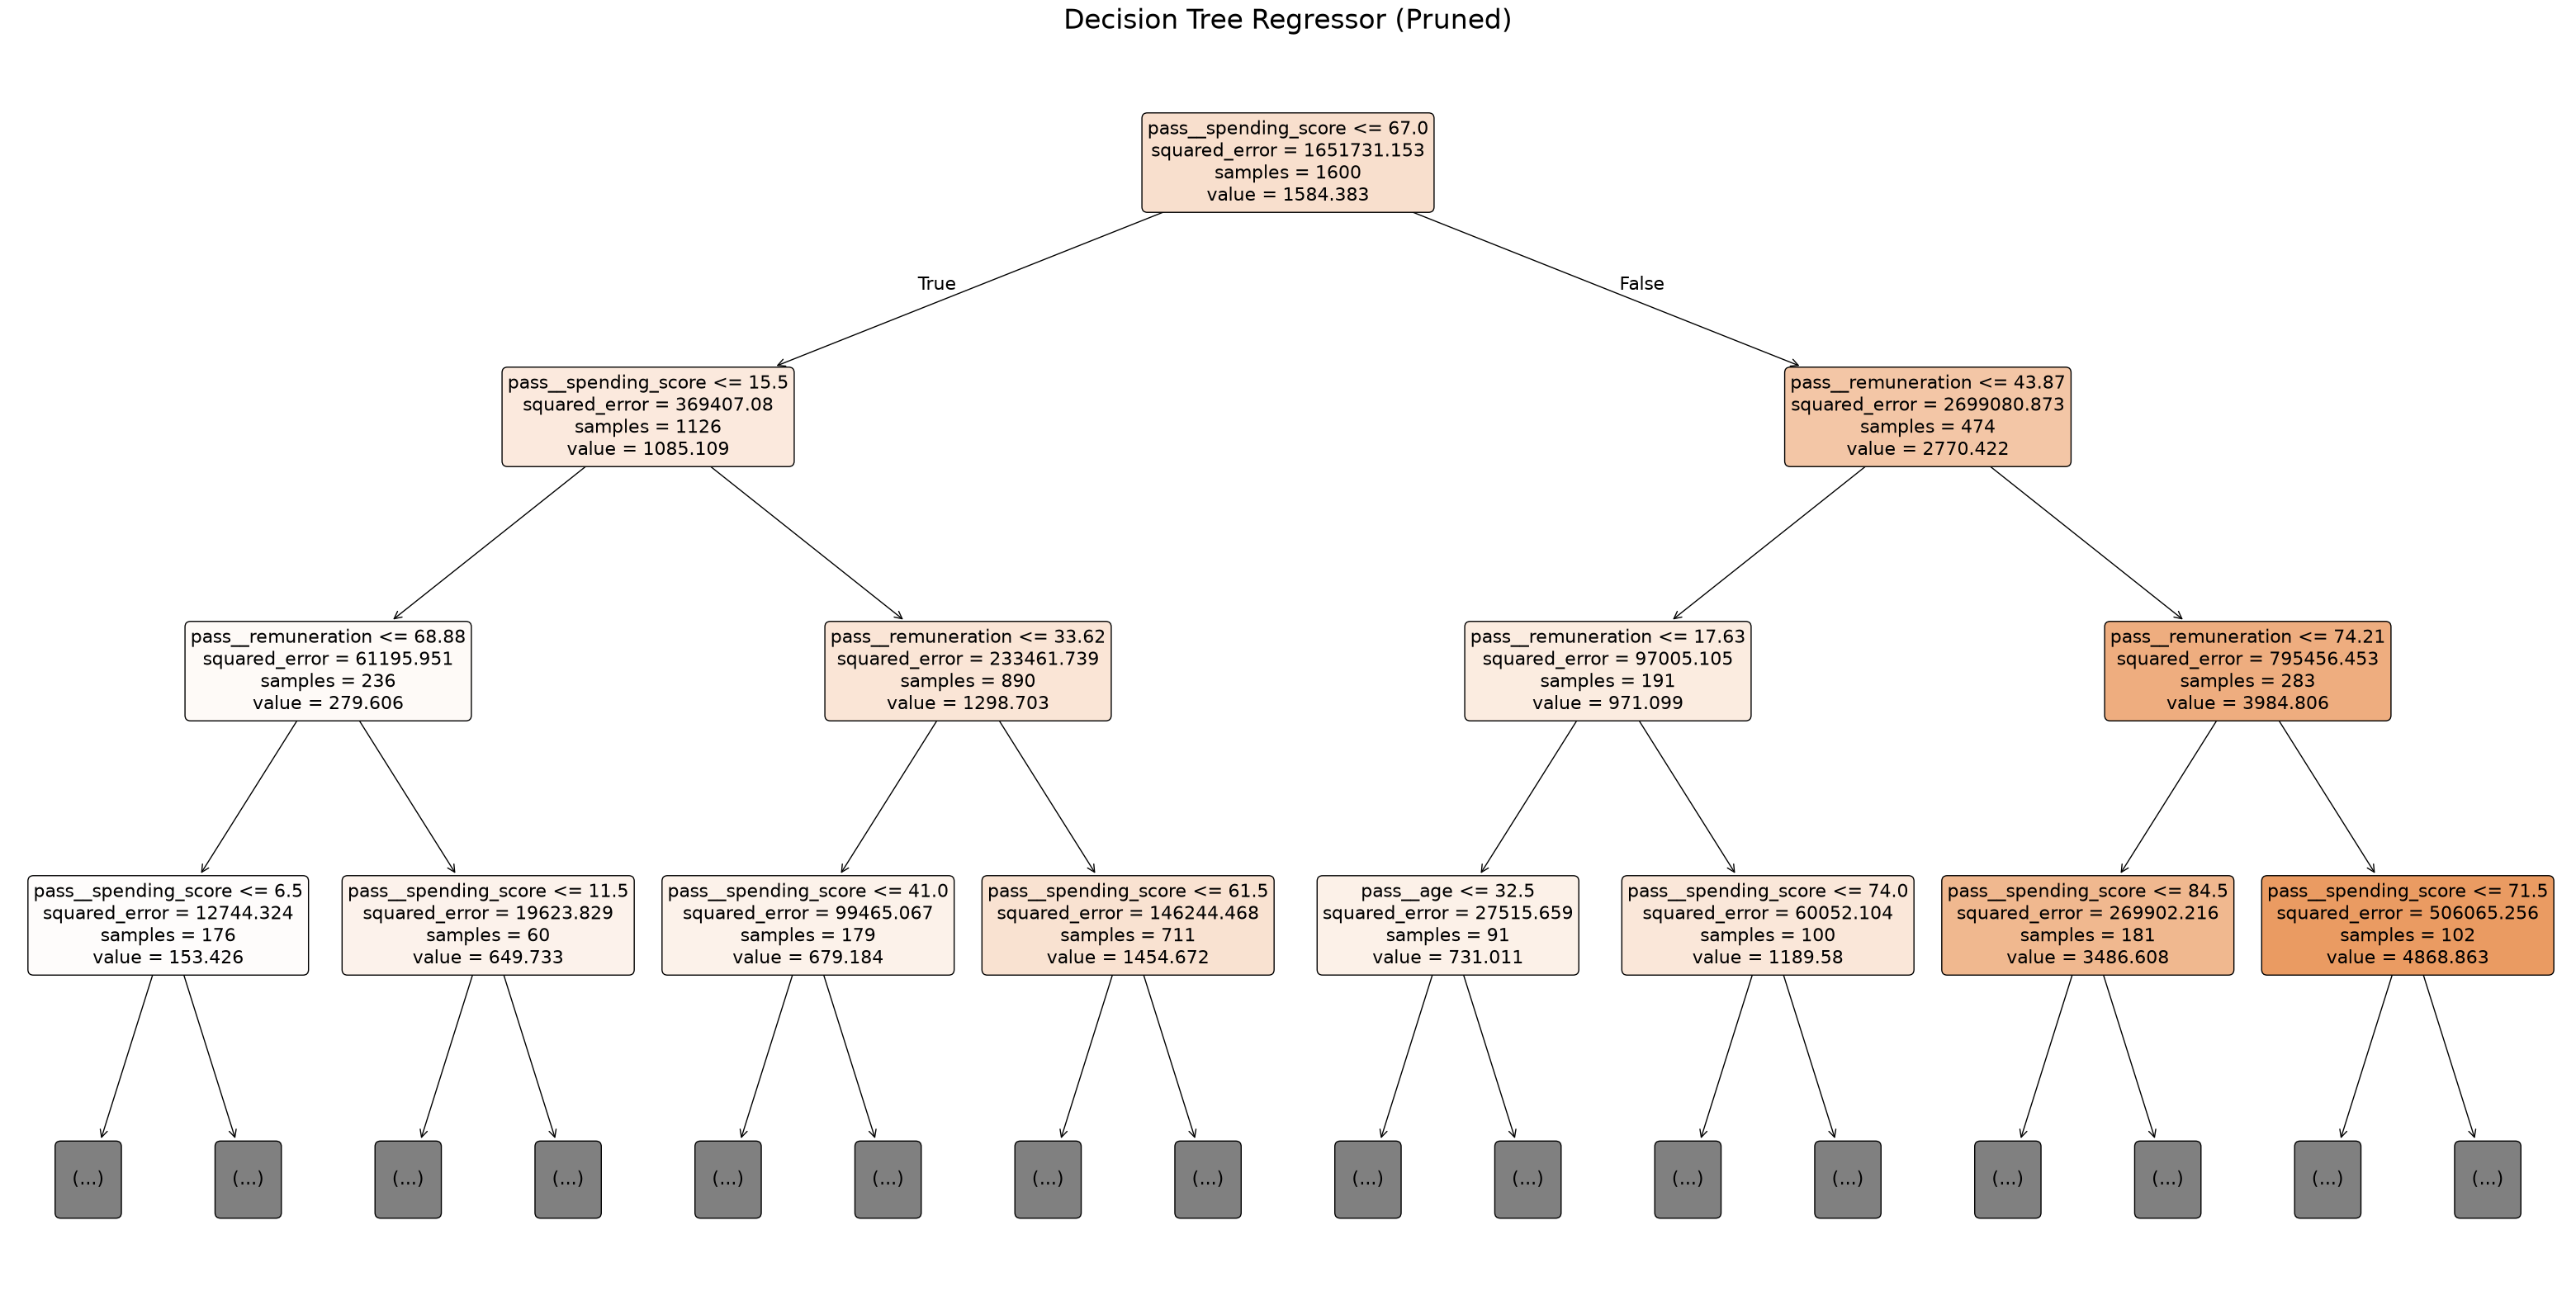

In [26]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Extract the fitted preprocessor and tree from the best GridSearchCV pipeline
best_preprocessor = grid_search.best_estimator_.named_steps['preprocessor']
best_tree = grid_search.best_estimator_.named_steps['regressor']

# Get the feature names after preprocessing
feature_names = best_preprocessor.get_feature_names_out()

plt.figure(figsize=(40, 20))
plot_tree(best_tree, feature_names=feature_names, filled=True,
          max_depth=3, rounded=True, fontsize=16)
plt.title("Decision Tree Regressor (Pruned)", fontsize=24)
plt.show()

**Insights from Decision Tree**

Both spending_score and remuneration are key predictors, appearing frequently in the early splits of the tree. Higher income tends to be associated with higher loyalty points. The right branches of the tree where spending_score exceeds 67 and remuneration is greater than 43.87 lead to higher predicted values, such as 3984, 4868 etc. In contrast, customers with lower spending and income are clustered on the left branches, with predicted values like 153, reinforcing the link between economic activity and loyalty point accumulation.

**Use Cases:**
- Target high-value customers (right-side branches) with premium rewards or exclusive offers.
- Identify low-engagement segments (left branches) to improve retention with basic incentives.